# Forecasting Monthly Sales for a New Beverage Product
### AI in Operations: Session II Lab Activity

**Scenario (from the brief).** A beverage company has launched a new **flavoured water** product in regional markets. It has collected **monthly sales data for the first year** and wants to **forecast demand for the upcoming months** so it can optimise **production and distribution**. We apply forecasting models (Naive, ARIMA, Random Forest, XGBoost) and evaluate them with **MAPE and WAPE**. An **LLM** then interprets the results from the live computed numbers.

**Data.** Kaggle *Beverage Sales* (sebastianwillmann, MIT licence): 9.0 million synthetic wholesale/retail order lines across 16 German states, 2021-01-01 to 2023-12-30. Our "new flavoured water" is **Volvic Touch**, the only flavoured-style product in the Water category. The other eight waters are the company's established portfolio.

| Lab task | Section |
|---|---|
| 1. Preprocess: lag features / seasonal indicators | §5 |
| 2. Choose a forecasting model | §6 |
| 3. Train and test with an appropriate split | §7 |
| 4. Forecast the next 3 months | §9 |
| 5. Calculate MAPE and WAPE | §8 |
| 6. Plot actual vs predicted sales | §10 |
| 7. Interpret: seasonality/trend, best model and why, recommendations | §4, §11, §12 |
| **Must add LLM to create an interpretation based on real-time data** | §11 |

> **How the code is organised.** The modelling logic lives in the small `forecasting_core` package next to this notebook. The interactive dashboard runs the *same* package in the browser, so both always report identical numbers. This notebook calls it step by step and shows every intermediate result.

## 1. Setup

We import the libraries and the shared `forecasting_core` package, and fix the random seed so every run gives the same numbers. We also define one colour per model and use it in every chart, plus a light, low-glare chart style.

The LLM key is loaded from a git-ignored `.env` file. The notebook only reports *whether* a key is present and never prints it.

In [1]:
import json
import os
import sys
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap

# Project root = the folder that contains this notebook's parent folder
ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path.insert(0, str(ROOT))

import forecasting_core as fc
from forecasting_core import PipelineConfig, run_pipeline
from forecasting_core.analysis import analyse
from forecasting_core.data import (aggregate_monthly, build_series, export_dashboard_data, load_raw,
                                   observed_days, regional_units, validate)
from forecasting_core.features import build_feature_frame, feature_availability
from forecasting_core.llm_client import interpret, load_system_prompt
from forecasting_core.metrics import mape, wape
from forecasting_core.models import MODEL_ORDER, MODEL_REGISTRY

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=SyntaxWarning)  # harmless docstring warning inside google-genai
np.random.seed(42)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

RAW_CSV = ROOT / "synthetic_beverage_sales_data.csv"
DASHBOARD_DATA = ROOT / "dashboard" / "public" / "data"
PROMPT_PATH = ROOT / "prompts" / "interpretation_system.md"

# Load NVIDIA_API_KEY (and optional LLM_MODEL) from the project's .env without printing them
try:
    from dotenv import load_dotenv
    load_dotenv(ROOT / ".env")
except ImportError:
    pass
print("LLM key available:", bool(os.environ.get("NVIDIA_API_KEY")))

import scipy, sklearn, statsmodels, xgboost
print("forecasting_core", fc.__version__, "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scipy", scipy.__version__, "| scikit-learn", sklearn.__version__,
      "| statsmodels", statsmodels.__version__, "| xgboost", xgboost.__version__)

LLM key available: True


forecasting_core 1.0.0 | numpy 2.2.5 | pandas 2.3.3 | scipy 1.14.1 | scikit-learn 1.7.0 | statsmodels 0.14.4 | xgboost 2.1.4


**Chart style.** One fixed colour per model, used in every chart so a model is always recognisable. The order is checked to be colour-blind safe. Actuals are always drawn in near-black ink. The helper functions format axes (thousands as 'k', readable month labels), write data-driven interpretations, and format p-values.

In [2]:
# One fixed colour per model (validated colour-blind-safe order); actuals in near-black ink.
MODEL_COLORS = {
    "naive": "#2a78d6",           # blue
    "seasonal_naive": "#eb6834",  # orange
    "calendar_naive": "#1baf7a",  # aqua
    "arima": "#eda100",           # yellow
    "random_forest": "#e87ba4",   # magenta
    "xgboost": "#008300",         # green
}
MODEL_LABELS = {k: MODEL_REGISTRY[k].label for k in MODEL_ORDER}
INK, INK_2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
BLUE_RAMP = LinearSegmentedColormap.from_list(
    "blues", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": ["Segoe UI", "DejaVu Sans", "sans-serif"], "font.size": 10,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
    "lines.linewidth": 2, "lines.markersize": 5, "figure.dpi": 110,
})


def thousands(ax, axis="y"):
    fmt = matplotlib.ticker.FuncFormatter(lambda v, _: f"{v / 1000:,.0f}k")
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(fmt)


def month_ticks(ax, months, every=3):
    ax.set_xticks(range(0, len(months), every))
    ax.set_xticklabels([months[i] for i in range(0, len(months), every)], rotation=45, ha="right")


def say(text):
    # Render a data-driven interpretation as Markdown
    display(Markdown(text))


def fmt_p(p):
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"

## 2. Load the raw data and check its quality

The raw file has one row per product line in an order (about 9 million rows, 789 MB). We load it with explicit column types and run data-quality checks. The `assert` statements stop the notebook if any assumption is broken, so later results can be trusted.

In [3]:
raw = load_raw(RAW_CSV)
checks = validate(raw)
print(f"{checks['rows']:,} rows x {checks['columns']} columns, {checks['first_date']} to {checks['last_date']}")
pd.Series({k: v for k, v in checks.items() if k not in ("rows", "columns")}, name="value").to_frame()

8,999,910 rows x 11 columns, 2021-01-01 to 2023-12-30


,value
null_cells,0
duplicate_rows,0
duplicate_order_product,0
non_positive_quantity,0
non_positive_price,0
total_price_mismatches,0
b2c_rows_with_discount,0
first_date,2021-01-01
last_date,2023-12-30
days_with_sales,1094


**Quality gates.** These `assert` statements turn the checks above into hard requirements. If the data ever changed (new download, different file), the notebook would stop here instead of producing misleading results.

In [4]:
# The notebook stops here if any of these assumptions is violated
assert checks["null_cells"] == 0, "missing values found"
assert checks["duplicate_rows"] == 0 and checks["duplicate_order_product"] == 0, "duplicates found"
assert checks["non_positive_quantity"] == 0 and checks["non_positive_price"] == 0, "invalid quantities/prices"
assert checks["total_price_mismatches"] == 0, "Total_Price does not reconcile"
assert checks["b2c_rows_with_discount"] == 0, "unexpected B2C discounts"
assert checks["missing_days"] == ["2023-12-31"], checks["missing_days"]
print("All data-quality checks passed. Only gap: 2023-12-31 (the data ends on 30 Dec 2023).")
raw.head()

All data-quality checks passed. Only gap: 2023-12-31 (the data ends on 30 Dec 2023).


,Order_ID,Customer_ID,Customer_Type,Product,Category,Unit_Price,Quantity,Discount,Total_Price,Region,Order_Date
0,ORD1,CUS1496,B2B,Vio Wasser,Water,1.66,53,0.10,79.18,Baden-Württemberg,2023-08-23
1,ORD1,CUS1496,B2B,Evian,Water,1.56,90,0.10,126.36,Baden-Württemberg,2023-08-23
2,ORD1,CUS1496,B2B,Sprite,Soft Drinks,1.17,73,0.05,81.14,Baden-Württemberg,2023-08-23
3,ORD1,CUS1496,B2B,Rauch Multivitamin,Juices,3.22,59,0.10,170.98,Baden-Württemberg,2023-08-23
4,ORD1,CUS1496,B2B,Gerolsteiner,Water,0.87,35,0.10,27.40,Baden-Württemberg,2023-08-23


**Interpretation.** The data is unusually clean: no missing values, no duplicates, and every `Total_Price` equals `Unit_Price x Quantity x (1 - Discount)`. Discounts apply only to B2B customers. The single gap is **31 December 2023**, so December 2023 is a *partial month* (30 days). Rather than inventing the missing day, we keep the observed value and record the number of observed days. The calendar-aware models then handle it naturally.

## 3. Framing the scenario: monthly series for the new flavoured water

We aggregate the order lines to **monthly units sold** for each Water product x region x customer type, and count how many sales days each month has. **Units** are the forecasting target because production and distribution are planned in units. Revenue is kept for context.

* **New product:** Volvic Touch. Its first 12 months (Jan-Dec 2021) are the **launch year** described in the brief.
* **Established portfolio:** the eight other waters, used as comparable products.
* **Later months (2022-2023):** in the dashboard these arrive one month at a time, as "real-time" data.

In [5]:
water = aggregate_monthly(raw, category="Water")
days = observed_days(raw)
PRODUCT = "Volvic Touch"

full_records = build_series(water, days, PRODUCT)       # all 36 months
launch_records = full_records[:12]                       # first year = launch year
months_all = [r["month"] for r in full_records]

print("Water products:", sorted(water["Product"].unique()))
print("Regions:", water["Region"].nunique(), "| customer types:", sorted(water["Customer_Type"].unique()))
print(f"{PRODUCT}: {len(full_records)} months, launch year {launch_records[0]['month']} to {launch_records[-1]['month']}")
print("Observed days in the last month:", full_records[-1])
del raw  # free about 2 GB of memory; everything below uses the monthly table

Water products: ['Apollinaris', 'Evian', 'Gerolsteiner', 'San Pellegrino', 'Selters', 'Vio Wasser', 'Vittel', 'Volvic', 'Volvic Touch']
Regions: 16 | customer types: ['B2B', 'B2C']
Volvic Touch: 36 months, launch year 2021-01 to 2021-12
Observed days in the last month: {'month': '2023-12', 'units': 156938.0, 'days': 30, 'revenue': 204573.69}


**Plot.** The new product's monthly sales against the eight established waters, with the launch year shaded.

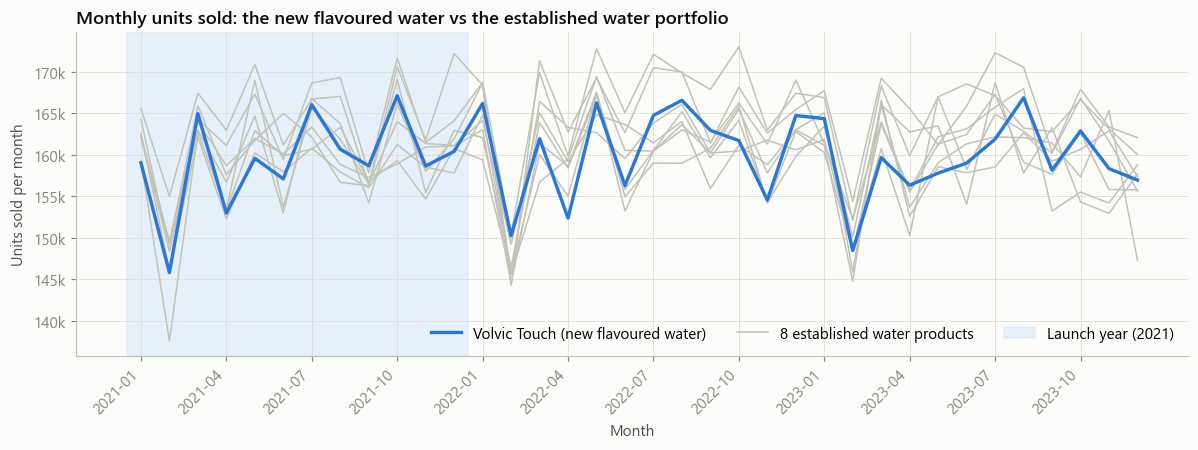

In [6]:
# Volvic Touch against the established water portfolio
portfolio = water.groupby(["month", "Product"])["units"].sum().unstack()
fig, ax = plt.subplots(figsize=(11, 4.2))
for p in portfolio.columns:
    if p != PRODUCT:
        ax.plot(range(len(portfolio)), portfolio[p], color="#c3c2b7", linewidth=1, zorder=1)
ax.plot(range(len(portfolio)), portfolio[PRODUCT], color=MODEL_COLORS["naive"], linewidth=2.2, zorder=3,
        label=f"{PRODUCT} (new flavoured water)")
ax.plot([], [], color="#c3c2b7", linewidth=1, label="8 established water products")
ax.axvspan(-0.5, 11.5, color="#cde2fb", alpha=0.45, zorder=0, label="Launch year (2021)")
month_ticks(ax, list(portfolio.index)); thousands(ax)
ax.set_title("Monthly units sold: the new flavoured water vs the established water portfolio")
ax.set_xlabel("Month"); ax.set_ylabel("Units sold per month")
ax.legend(loc="lower right", ncol=3)
plt.tight_layout(); plt.show()

**Interpretation.** Volvic Touch sells on the same scale as the established waters (about 160k units a month), and every product shows the same saw-tooth pattern: February is always lowest. The next section tests whether that pattern is real seasonality or simply the number of days in each month.

## 4. Exploring trend, seasonality and calendar effects

Before choosing models we test what patterns actually exist. All tests use the **daily sales rate** (units / sales days), so that the length of the month does not masquerade as seasonality:

* **Trend:** linear regression of the daily rate on time (p < 0.05 means a real trend).
* **Seasonality:** one-way ANOVA of the daily rate by calendar month. This needs each month observed at least twice (24+ months).
* **Calendar effect:** how much of the monthly variation is explained by the number of days (R²).
* **Autocorrelation (ACF):** whether a month's sales predict the next ones.

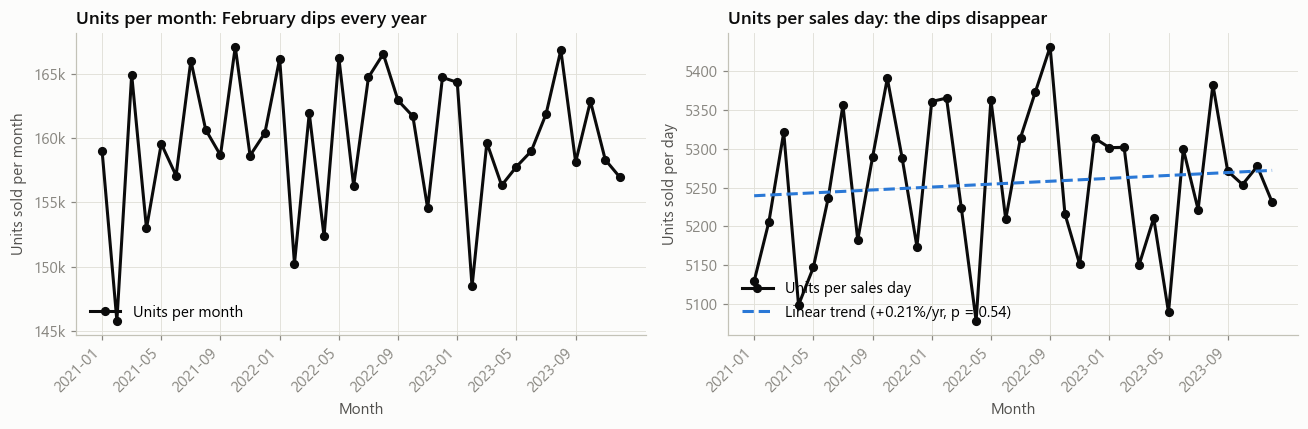

In [7]:
full_series = fc.MonthlySeries.from_records(full_records, name=PRODUCT)
stats_full = analyse(full_series, revenue=np.array([r["revenue"] for r in full_records]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(len(full_series))
ax = axes[0]
ax.plot(x, full_series.units, color=INK, marker="o", label="Units per month")
ax.set_title("Units per month: February dips every year")
month_ticks(ax, full_series.months, 4); thousands(ax)
ax.set_xlabel("Month"); ax.set_ylabel("Units sold per month"); ax.legend(loc="lower left")
ax = axes[1]
ax.plot(x, full_series.daily_rate, color=INK, marker="o", label="Units per sales day")
ax.plot(x, stats_full["trend_units_per_day"]["fitted"], color=MODEL_COLORS["naive"], linestyle="--",
        label=f"Linear trend ({stats_full['trend_units_per_day']['pct_per_year']:+.2f}%/yr, "
              f"p = {stats_full['trend_units_per_day']['p_value']:.2f})")
ax.set_title("Units per sales day: the dips disappear")
month_ticks(ax, full_series.months, 4)
ax.set_xlabel("Month"); ax.set_ylabel("Units sold per day"); ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

**Seasonality, calendar and memory.** Three views of the same question: (1) the average daily rate for each calendar month, with error bars showing how much each month varies from year to year; (2) units against the number of sales days in the month; (3) the autocorrelation of the daily rate with its noise band. The table summarises every statistic.

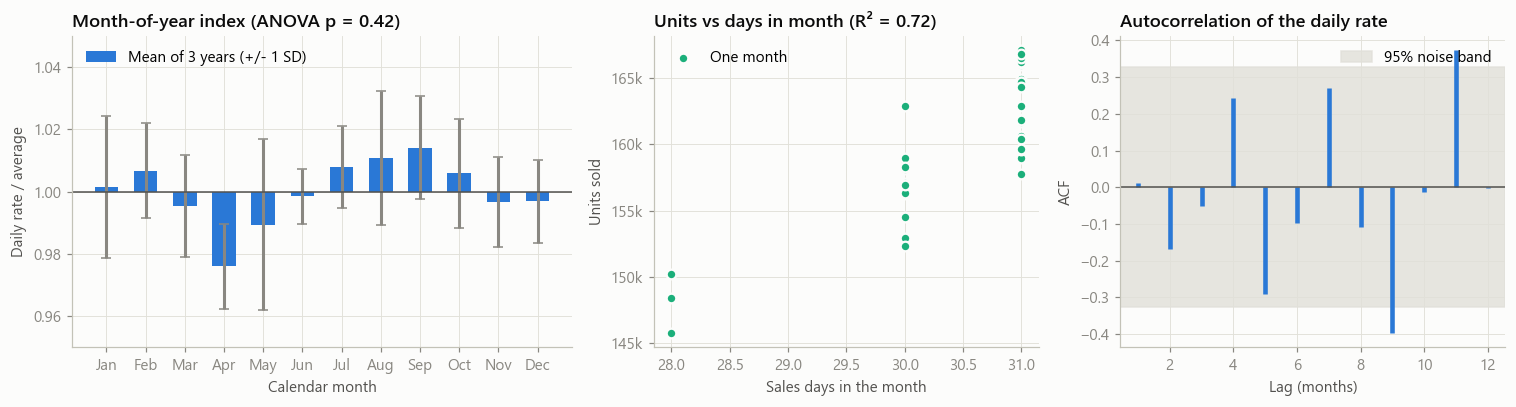

,value
statistic,
Volume trend (% per year),+0.21
Volume trend p-value,p = 0.538
Seasonality ANOVA p-value,p = 0.417
Peak-to-trough spread (%),3.82
R² explained by days in month,0.72
ACF lag 1 (bound +/-),0.01 (0.33)
CV of monthly units (%),3.34
CV of daily rate (%),1.76
Revenue/day trend (% per year),+2.77


In [8]:
seas = stats_full["seasonality"]
acf_ = stats_full["acf"]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1.3, 1, 1]})

ax = axes[0]
idx = pd.DataFrame(seas["index"])
ax.bar(idx["month"], idx["index"] - 1, bottom=1, color=MODEL_COLORS["naive"], width=0.6,
       yerr=idx["sd"], ecolor=MUTED, capsize=3, label="Mean of 3 years (+/- 1 SD)")
ax.axhline(1, color=INK_2, linewidth=1)
ax.set_ylim(0.95, 1.05)
ax.set_title(f"Month-of-year index (ANOVA p = {seas['p_value']:.2f})")
ax.set_xlabel("Calendar month"); ax.set_ylabel("Daily rate / average"); ax.legend(loc="upper left")

ax = axes[1]
ax.scatter(full_series.days, full_series.units, color=MODEL_COLORS["calendar_naive"], s=40, edgecolor=SURFACE,
           linewidth=1.5, zorder=3, label="One month")
ax.set_title(f"Units vs days in month (R² = {stats_full['calendar']['r2']:.2f})")
ax.set_xlabel("Sales days in the month"); ax.set_ylabel("Units sold"); thousands(ax); ax.legend(loc="upper left")

ax = axes[2]
ax.vlines(acf_["lags"], 0, acf_["acf"], color=MODEL_COLORS["naive"], linewidth=3)
ax.axhspan(-acf_["bound"], acf_["bound"], color=GRID, alpha=0.8, label="95% noise band")
ax.axhline(0, color=INK_2, linewidth=1)
ax.set_title("Autocorrelation of the daily rate")
ax.set_xlabel("Lag (months)"); ax.set_ylabel("ACF"); ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

tr, rv = stats_full["trend_units_per_day"], stats_full["revenue_trend"]
pd.DataFrame({
    "statistic": ["Volume trend (% per year)", "Volume trend p-value", "Seasonality ANOVA p-value",
                  "Peak-to-trough spread (%)", "R² explained by days in month", "ACF lag 1 (bound +/-)",
                  "CV of monthly units (%)", "CV of daily rate (%)", "Revenue/day trend (% per year)",
                  "Revenue trend p-value"],
    "value": [f"{tr['pct_per_year']:+.2f}", fmt_p(tr["p_value"]), fmt_p(seas["p_value"]),
              f"{seas['peak_trough_pct']:.2f}", f"{stats_full['calendar']['r2']:.2f}",
              f"{acf_['acf'][0]:.2f} ({acf_['bound']:.2f})",
              f"{stats_full['volatility']['cv_units_pct']:.2f}", f"{stats_full['volatility']['cv_daily_rate_pct']:.2f}",
              f"{rv['pct_per_year']:+.2f}", fmt_p(rv["p_value"])],
}).set_index("statistic")

**Interpretation, generated from the statistics.** Every number in the text below is taken directly from the results above, so it updates automatically if the data changes.

In [9]:
tr, rv, cal = stats_full["trend_units_per_day"], stats_full["revenue_trend"], stats_full["calendar"]
say(f'''**Interpretation (Volvic Touch, 36 months).**
* **No volume trend:** the daily rate changes by {tr['pct_per_year']:+.2f}% a year ({fmt_p(tr['p_value'])}), far from significant.
* **No seasonality:** the month-of-year ANOVA gives {fmt_p(seas['p_value'])}. The peak-to-trough spread of {seas['peak_trough_pct']:.1f}% is within the year-to-year noise (see the error bars).
* **The calendar is the only systematic pattern:** the number of days in a month explains **R² = {cal['r2']:.2f}** of the monthly variation. That is the February dip.
* **No memory:** the lag-1 autocorrelation ({acf_['acf'][0]:.2f}) is inside the noise band (+/-{acf_['bound']:.2f}), so last month says little about next month beyond the overall level. A few longer lags poke slightly outside the band, which is expected by chance when 12 lags are tested at once.
* **Revenue does grow** ({rv['pct_per_year']:+.2f}% a year, {fmt_p(rv['p_value'])}), but this comes from **price increases**, not volume.

**What this means for model choice:** models that use the days-in-month indicator should do best. Seasonal and lag-based models have little real signal to learn, so complex models may over-fit.''')

**Interpretation (Volvic Touch, 36 months).**
* **No volume trend:** the daily rate changes by +0.21% a year (p = 0.538), far from significant.
* **No seasonality:** the month-of-year ANOVA gives p = 0.417. The peak-to-trough spread of 3.8% is within the year-to-year noise (see the error bars).
* **The calendar is the only systematic pattern:** the number of days in a month explains **R² = 0.72** of the monthly variation. That is the February dip.
* **No memory:** the lag-1 autocorrelation (0.01) is inside the noise band (+/-0.33), so last month says little about next month beyond the overall level. A few longer lags poke slightly outside the band, which is expected by chance when 12 lags are tested at once.
* **Revenue does grow** (+2.77% a year, p < 0.001), but this comes from **price increases**, not volume.

**What this means for model choice:** models that use the days-in-month indicator should do best. Seasonal and lag-based models have little real signal to learn, so complex models may over-fit.

### 4.1 Can the new product borrow seasonality from the established portfolio?

A new product's first year cannot reveal seasonality on its own, because each month is seen only once. A standard remedy is to borrow the seasonal profile of **comparable products** with longer histories. We run the same tests on all nine water products.

In [10]:
rows = []
for product in sorted(water["Product"].unique()):
    recs = build_series(water, days, product)
    s = fc.MonthlySeries.from_records(recs)
    a = analyse(s)
    rows.append({"product": product,
                 "mean units / month": round(a["volatility"]["mean_units"]),
                 "trend %/yr": round(a["trend_units_per_day"]["pct_per_year"], 2),
                 "trend p": round(a["trend_units_per_day"]["p_value"], 3),
                 "seasonality p": round(a["seasonality"]["p_value"], 3),
                 "R² days": round(a["calendar"]["r2"], 2)})
portfolio_tests = pd.DataFrame(rows).set_index("product")
portfolio_tests

,mean units / month,trend %/yr,trend p,seasonality p,R² days
product,,,,,
Apollinaris,160294,-0.12,0.784,0.962,0.58
Evian,159601,-0.18,0.663,0.412,0.61
Gerolsteiner,158465,0.69,0.060,0.456,0.75
San Pellegrino,164853,0.19,0.591,0.818,0.77
Selters,160182,0.12,0.767,0.243,0.70
Vio Wasser,159704,-0.12,0.739,0.485,0.71
Vittel,164475,0.46,0.193,0.619,0.75
Volvic,159402,0.31,0.489,0.256,0.62
Volvic Touch,159716,0.21,0.538,0.417,0.72


**Interpretation, generated from the portfolio table.**

In [11]:
n_seasonal = int((portfolio_tests["seasonality p"] < 0.05).sum())
n_trend = int((portfolio_tests["trend p"] < 0.05).sum())
say(f'''**Interpretation.** {n_seasonal} of 9 water products show significant seasonality and {n_trend} of 9 show a significant volume trend. Every product has the same strong calendar effect (R² {portfolio_tests['R² days'].min():.2f} to {portfolio_tests['R² days'].max():.2f}). So there is **no seasonal profile to borrow** beyond the number of days in each month. For the launch year this is useful news: the right "seasonal indicator" for the new product is the calendar, and it is known in advance for every future month.''')

**Interpretation.** 0 of 9 water products show significant seasonality and 0 of 9 show a significant volume trend. Every product has the same strong calendar effect (R² 0.58 to 0.77). So there is **no seasonal profile to borrow** beyond the number of days in each month. For the launch year this is useful news: the right "seasonal indicator" for the new product is the calendar, and it is known in advance for every future month.

### 4.2 Regional markets and customer types

Distribution is planned by region, so we look at how Volvic Touch volume is spread across the 16 states and between business (B2B) and consumer (B2C) customers.

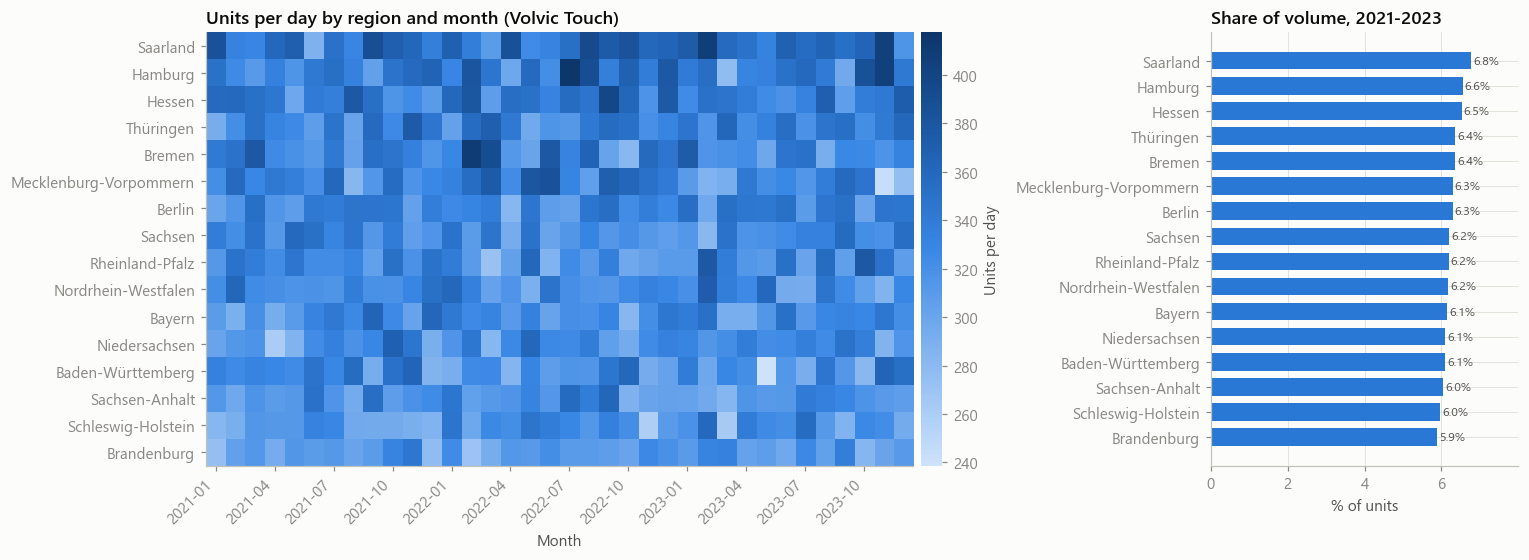

**Interpretation.** Volume is spread fairly evenly: the largest state, **Saarland**, takes 6.8% and the smallest, Brandenburg, 5.9%. **B2B customers buy 78%** of units, because business orders are larger. Single-region series are much noisier (daily-rate variation 5.5% to 9.3%, against 1.8% nationally). Regional plans are therefore best made by **allocating the national forecast by regional share**, rather than forecasting each state separately.

In [12]:
vt = water[water["Product"] == PRODUCT]
by_region = vt.pivot_table(index="Region", columns="month", values="units", aggfunc="sum")
day_vec = np.array([days[pd.Period(m, "M")] for m in by_region.columns])
rate_region = by_region / day_vec  # units per day removes the month-length effect
order = by_region.sum(axis=1).sort_values(ascending=False).index

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [2.4, 1]})
ax = axes[0]
im = ax.imshow(rate_region.loc[order].to_numpy(), aspect="auto", cmap=BLUE_RAMP)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order)
month_ticks(ax, list(by_region.columns), 3); ax.grid(False)
ax.set_title("Units per day by region and month (Volvic Touch)")
ax.set_xlabel("Month")
cb = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.01); cb.set_label("Units per day"); cb.outline.set_visible(False)

ax = axes[1]
share = (by_region.sum(axis=1) / by_region.to_numpy().sum() * 100).loc[order]
ax.barh(range(len(share)), share.values, color=MODEL_COLORS["naive"], height=0.7)
ax.set_yticks(range(len(share))); ax.set_yticklabels(order); ax.invert_yaxis()
for i, v in enumerate(share.values):
    ax.text(v + 0.05, i, f"{v:.1f}%", va="center", color=INK_2, fontsize=8)
ax.set_title("Share of volume, 2021-2023"); ax.set_xlabel("% of units"); ax.set_xlim(0, share.max() * 1.18)
plt.tight_layout(); plt.show()

ct = vt.groupby("Customer_Type")["units"].sum()
region_cv = (by_region.div(day_vec).std(axis=1) / by_region.div(day_vec).mean(axis=1) * 100)
say(f'''**Interpretation.** Volume is spread fairly evenly: the largest state, **{order[0]}**, takes {share.iloc[0]:.1f}% and the smallest, {order[-1]}, {share.iloc[-1]:.1f}%. **B2B customers buy {ct['B2B'] / ct.sum() * 100:.0f}%** of units, because business orders are larger. Single-region series are much noisier (daily-rate variation {region_cv.min():.1f}% to {region_cv.max():.1f}%, against {stats_full['volatility']['cv_daily_rate_pct']:.1f}% nationally). Regional plans are therefore best made by **allocating the national forecast by regional share**, rather than forecasting each state separately.''')

## 5. Task 1: Preprocessing and feature engineering

The tree-based models (Random Forest, XGBoost) need explicit features. Every feature for month *t* uses only information available **before** *t* (lags), or facts known in advance (calendar), so nothing leaks from the future.

| Feature | Meaning | Why |
|---|---|---|
| `lag_1`, `lag_2`, `lag_3` | units 1-3 months earlier | recent level |
| `rolling_mean_3` | mean of the last 3 months | smoothed level |
| `days_in_month` | sales days in the month | **the calendar effect found in §4** |
| `month_sin`, `month_cos` | calendar month on a circle | seasonal indicator (Dec sits next to Jan) |
| `lag_12` | same month last year | yearly seasonality, **only once 24+ months exist** |
| `t` | months since launch | used for the trend test, not given to trees (trees cannot extrapolate a trend) |

Below is the feature table for the **launch year**. The first three months have no lag values: they are lost as training rows.

In [13]:
launch_series = fc.MonthlySeries.from_records(launch_records, name=PRODUCT)
feat_launch = build_feature_frame(launch_series)
feat_launch.round(3)

,units,t,daily_rate,lag_1,lag_2,lag_3,rolling_mean_3,days_in_month,month_sin,month_cos
2021-01,159013.0,1,5129.452,NaN,NaN,NaN,NaN,31.0,0.500,0.866
2021-02,145774.0,2,5206.214,159013.0,NaN,NaN,NaN,28.0,0.866,0.500
2021-03,164952.0,3,5321.032,145774.0,159013.0,NaN,NaN,31.0,1.000,0.000
2021-04,152966.0,4,5098.867,164952.0,145774.0,159013.0,156579.667,30.0,0.866,-0.500
2021-05,159563.0,5,5147.194,152966.0,164952.0,145774.0,154564.000,31.0,0.500,-0.866
2021-06,157079.0,6,5235.967,159563.0,152966.0,164952.0,159160.333,30.0,0.000,-1.000
2021-07,166034.0,7,5355.935,157079.0,159563.0,152966.0,156536.000,31.0,-0.500,-0.866
2021-08,160660.0,8,5182.581,166034.0,157079.0,159563.0,160892.000,31.0,-0.866,-0.500
2021-09,158666.0,9,5288.867,160660.0,166034.0,157079.0,161257.667,30.0,-1.000,-0.000
2021-10,167105.0,10,5390.484,158666.0,160660.0,166034.0,161786.667,31.0,-0.866,0.500


**Which features are possible with how much history.** This compares the launch year (12 months) with three years (36 months).

In [14]:
print("Feature availability with 12 months (launch year) vs 36 months (three years):")
avail = pd.DataFrame(feature_availability(12))[["feature", "available", "note"]]
avail.insert(2, "available at 36 months", [a["available"] for a in feature_availability(36)])
avail.rename(columns={"available": "available at 12 months"})

Feature availability with 12 months (launch year) vs 36 months (three years):


,feature,available at 12 months,available at 36 months,note
0,days_in_month,True,True,Known for every month; the only seasonal indic...
1,month_sin / month_cos,True,True,"Usable, but each calendar month appears only o..."
2,"lag_1..lag_3, rolling_mean_3",True,True,Costs the first 3 months as training rows (9 r...
3,lag_12,False,True,"Needs 24+ months (12 to look back, 12 to learn..."
4,t (trend index),True,True,Used for the trend test; not given to tree mod...


**Interpretation: the limits of a first year.**
* With 12 months, three lags and a 3-month test window, the tree models have only **6 training rows** for testing (9 for the final forecast). That is far too few to learn reliable patterns.
* `lag_12` and seasonal ARIMA are impossible in year 1, and `month_sin`/`month_cos` cannot learn month effects when each month has been seen once.
* `days_in_month` is the one seasonal indicator that is both meaningful and known in advance. §4 showed it carries the real signal.

## 6. Task 2: Choosing the forecasting models

We compare six models, from the simplest benchmark to machine learning, all on **exactly the same split and horizon**:

In [15]:
model_table = pd.DataFrame([
    {"model": cls.label, "family": cls.family, "min. training months": cls.min_train,
     "uncertainty range": {"analytic": "analytic (sigma x sqrt h)", "native": "native ARIMA intervals",
                           "empirical": "empirical, from backtest errors (approximate)"}[cls.interval_type],
     "how it forecasts": cls.description}
    for cls in MODEL_REGISTRY.values()]).set_index("model")
model_table

,family,min. training months,uncertainty range,how it forecasts
model,,,,
Naive,baseline,1,analytic (sigma x sqrt h),Next months = the last observed month. The ben...
Seasonal Naive,baseline,12,analytic (sigma x sqrt h),Next months = the same months one year earlier...
Calendar-adjusted Naive,baseline,1,analytic (sigma x sqrt h),Last month's sales per day x the number of day...
ARIMA,statistical,6,native ARIMA intervals,"ARIMA(p,d,q) with a days-in-month regressor; o..."
Random Forest,machine learning,7,"empirical, from backtest errors (approximate)","100 shallow decision trees averaged, trained o..."
XGBoost,machine learning,7,"empirical, from backtest errors (approximate)",Gradient-boosted shallow trees with strong reg...


**Why these six.**
* **Naive** is the benchmark the brief names. A model is only useful if it beats "next month = last month".
* **Seasonal Naive** is the standard seasonal benchmark. It needs a full year *before* the test window, so it is disabled in the launch-year analysis.
* **Calendar-adjusted Naive** applies §4's finding directly: it carries forward last month's *daily* rate and multiplies it by the days in each future month.
* **ARIMA** is the classical time-series model from the brief. A days-in-month regressor gives it the calendar effect. Its order (p,d,q) is chosen by AICc on the training data only, from a deliberately small grid so it cannot over-fit a short history.
* **Random Forest** and **XGBoost** are the ML options from the brief, using the §5 features. They are kept shallow and regularised because the samples are tiny. They forecast **recursively**: each month's prediction becomes the next month's lag, so no future actuals are used.

**Hypothesis (to test, not assume):** given §4, the calendar-aware models (Calendar-adjusted Naive, ARIMA) should beat Naive, and the ML models should struggle with so few rows.

## 7. Task 3: Train and test with a chronological split

**Why chronological, never random:** a random split would let a model learn from months *after* the ones it is tested on, which is impossible in practice and makes errors look smaller than they are. We always train on earlier months and test on the months that follow.

**Two scenarios, same rules:**

| | A. Launch year (the brief's scenario) | B. Three years of history |
|---|---|---|
| Data | Jan-Dec 2021 (12 months) | Jan 2021 - Dec 2023 (36 months) |
| Train | Jan-Sep 2021 (9) | Jan 2021 - Sep 2023 (33) |
| Test | Oct-Dec 2021 (3) | Oct-Dec 2023 (3) |
| Final forecast (refit on all data) | Jan-Mar 2022 | Jan-Mar 2024 |

**Why a 3-month test window:** it equals the 3-month planning horizon in the brief. With only 12 months, a longer test window would leave too little to train on.

**Rolling-origin backtest:** one 3-month window is a small sample. So we also repeat the "train, then forecast 3 months" exercise at several successive cut-off points (up to 12; 3 in the launch year, where the ML models need at least 7 training months). The last cut-off is the main split. Models are **ranked by their pooled backtest WAPE**, which is more reliable than a single window.

In [16]:
CONFIG = PipelineConfig(test_size=3, horizon=3, max_backtest_origins=12)


def context_for(records, view):
    notes = []
    if records[-1]["month"] == "2023-12":
        notes.append("December 2023 contains 30 of 31 days because the data ends on 30 Dec 2023.")
    return {"product": PRODUCT, "region": "All regions", "customer_type": "All customers", "view": view,
            "unit": "units", "data_version": 1, "notes": notes}


def regional_for(records):
    return regional_units(water, PRODUCT, [r["month"] for r in records])


res_launch = run_pipeline(launch_records, CONFIG, context_for(launch_records, "Launch year (first 12 months)"),
                          regional_for(launch_records))
res_full = run_pipeline(full_records, CONFIG, context_for(full_records, "Three years of history (36 months)"),
                        regional_for(full_records))

for name, r in [("A. Launch year", res_launch), ("B. Three years", res_full)]:
    m = r["meta"]
    print(f"{name}: train {m['train_months'][0]}..{m['train_months'][1]} ({m['n_train']} months) | "
          f"test {m['test_months'][0]}..{m['test_months'][1]} | backtest cut-offs {m['backtest_origins']}")
    print(f"   ARIMA order identified on training data: {r['models']['arima']['params']['order']}")
    for k in MODEL_ORDER:
        if not r["models"][k]["available"]:
            print(f"   {MODEL_LABELS[k]} disabled: {r['models'][k]['reason']}")

A. Launch year: train 2021-01..2021-09 (9 months) | test 2021-10..2021-12 | backtest cut-offs ['2021-07', '2021-08', '2021-09']
   ARIMA order identified on training data: [0, 1, 0]
   Seasonal Naive disabled: Needs a full year (12 months) of training history to look back on; has 9.
B. Three years: train 2021-01..2023-09 (33 months) | test 2023-10..2023-12 | backtest cut-offs ['2022-10', '2022-11', '2022-12', '2023-01', '2023-02', '2023-03', '2023-04', '2023-05', '2023-06', '2023-07', '2023-08', '2023-09']
   ARIMA order identified on training data: [0, 0, 0]


**Plot of the split.** For both scenarios: training months, test months, and the forecast months that follow.

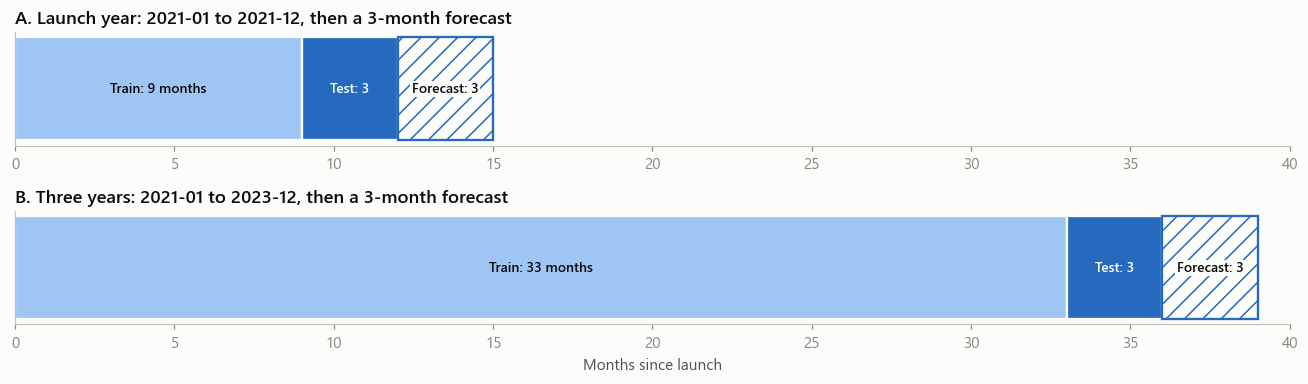

In [17]:
# Visualise the split for both scenarios
fig, axes = plt.subplots(2, 1, figsize=(12, 3.6), sharex=False)
for ax, (name, r) in zip(axes, [("A. Launch year", res_launch), ("B. Three years", res_full)]):
    months = [s["month"] for s in r["series"]]
    n_train = r["meta"]["n_train"]
    t, h = r["meta"]["test_size"], r["meta"]["horizon"]
    segments = [(0, n_train, "#9ec5f4", INK, f"Train: {n_train} months"),
                (n_train, t, "#256abf", "#ffffff", f"Test: {t}"),
                (len(months), h, SURFACE, INK, f"Forecast: {h}")]
    for left, width, color, ink, text in segments:
        ax.barh(0, width, left=left, color=color, height=0.5, edgecolor="#256abf" if color == SURFACE else SURFACE,
                linewidth=1.5, hatch="//" if color == SURFACE else None)
        ax.text(left + width / 2, 0, text, ha="center", va="center", color=ink, fontsize=9, fontweight="semibold",
                bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1) if color == SURFACE else None)
    ax.set_yticks([]); ax.grid(False); ax.set_xlim(0, 40)
    ax.set_title(f"{name}: {months[0]} to {months[-1]}, then a {h}-month forecast")
axes[1].set_xlabel("Months since launch")
plt.tight_layout(); plt.show()

## 8. Task 5: Evaluating performance with MAPE and WAPE

With $A_t$ the actual and $F_t$ the forecast for month $t$:

$$\text{MAPE} = \frac{100}{n'}\sum_{t:\,|A_t|>\varepsilon}\frac{|A_t-F_t|}{|A_t|} \qquad\qquad \text{WAPE} = 100\,\frac{\sum_t |A_t-F_t|}{\sum_t |A_t|}$$

* **MAPE** averages the percentage error of each month. It divides by each actual, so a month with zero (or near-zero) sales would make it explode. Such months (|A| <= 1 unit) are **excluded and counted**, and if every month is excluded MAPE is reported as *undefined*, never as 0.
* **WAPE** divides total absolute error by total volume. It is robust to individual zero months and weights errors by volume, which is what matters for production. **WAPE is our primary ranking metric.**
* **Bias** = 100 x sum(F - A) / sum(A) shows over-forecasting (+) vs under-forecasting (-), i.e. excess stock vs stock-out risk.

### 8.1 Cross-check against a hand calculation

Naive forecast for the launch-year test window: every month = the September 2021 value, **158,666** units.

| Month | Actual A | Forecast F | abs(A - F) | abs(A - F) / A |
|---|---|---|---|---|
| Oct 2021 | 167,105 | 158,666 | 8,439 | 5.0501% |
| Nov 2021 | 158,642 | 158,666 | 24 | 0.0151% |
| Dec 2021 | 160,396 | 158,666 | 1,730 | 1.0786% |
| **Total** | **486,143** | | **10,193** | |

MAPE = (5.0501 + 0.0151 + 1.0786) / 3 = **2.048%** · WAPE = 10,193 / 486,143 = **2.097%**

In [18]:
actual = np.array([167105, 158642, 160396], dtype=float)
naive_fc = np.repeat(158666.0, 3)
hand_mape = np.mean(np.abs(actual - naive_fc) / actual) * 100
hand_wape = np.abs(actual - naive_fc).sum() / actual.sum() * 100

# The library functions and the pipeline must agree with the hand calculation
assert abs(mape(actual, naive_fc)["value"] - hand_mape) < 1e-12
assert abs(wape(actual, naive_fc)["value"] - hand_wape) < 1e-12
assert abs(res_launch["models"]["naive"]["metrics_test"]["mape"] - 2.0479) < 1e-4
assert abs(res_launch["models"]["naive"]["metrics_test"]["wape"] - 2.0967) < 1e-4
# Zero handling: a zero actual is excluded from MAPE (and counted), WAPE stays defined
z = mape([100, 0, 200], [110, 5, 180])
assert z["n_excluded"] == 1 and abs(z["value"] - 10.0) < 1e-12
assert mape([0, 0], [1, 1])["value"] is None
print(f"Hand calculation  MAPE {hand_mape:.4f}%  WAPE {hand_wape:.4f}%  -> matches the pipeline. Zero handling verified.")

Hand calculation  MAPE 2.0479%  WAPE 2.0967%  -> matches the pipeline. Zero handling verified.


### 8.2 Results for all models

In [19]:
def metrics_table(r):
    rows = []
    for k in MODEL_ORDER:
        m = r["models"][k]
        if not m["available"]:
            rows.append({"model": m["label"], "test MAPE %": None, "test WAPE %": None, "test bias %": None,
                         "backtest MAPE %": None, "backtest WAPE %": None, "rank": "n/a (disabled)"})
            continue
        bt = m["backtest"]["metrics"] or {}
        rows.append({"model": m["label"], "test MAPE %": m["metrics_test"]["mape"],
                     "test WAPE %": m["metrics_test"]["wape"], "test bias %": m["metrics_test"]["bias"],
                     "backtest MAPE %": bt.get("mape"), "backtest WAPE %": bt.get("wape"),
                     "rank": r["ranking"].index(k) + 1})
    return pd.DataFrame(rows).set_index("model").round(2)


print("A. Launch year  (test Oct-Dec 2021; backtest", len(res_launch["meta"]["backtest_origins"]), "cut-offs)")
display(metrics_table(res_launch))
print("B. Three years  (test Oct-Dec 2023; backtest", len(res_full["meta"]["backtest_origins"]), "cut-offs)")
display(metrics_table(res_full))

A. Launch year  (test Oct-Dec 2021; backtest 3 cut-offs)


,test MAPE %,test WAPE %,test bias %,backtest MAPE %,backtest WAPE %,rank
model,,,,,,
Naive,2.05,2.10,-2.09,2.35,2.37,4
Seasonal Naive,NaN,NaN,NaN,NaN,NaN,n/a (disabled)
Calendar-adjusted Naive,1.37,1.38,0.09,1.91,1.92,2
ARIMA,1.38,1.38,0.23,1.97,1.97,3
Random Forest,1.56,1.60,-1.56,1.73,1.78,1
XGBoost,1.03,1.05,-0.76,2.81,2.83,5


B. Three years  (test Oct-Dec 2023; backtest 12 cut-offs)


,test MAPE %,test WAPE %,test bias %,backtest MAPE %,backtest WAPE %,rank
model,,,,,,
Naive,1.26,1.28,-0.78,3.45,3.42,6
Seasonal Naive,2.69,2.67,0.59,2.08,2.07,3
Calendar-adjusted Naive,1.52,1.50,1.43,1.98,1.99,2
ARIMA,1.40,1.38,1.11,1.29,1.29,1
Random Forest,2.15,2.13,0.28,2.27,2.25,4
XGBoost,2.33,2.31,0.78,2.30,2.29,5


**Chart of the metrics.** WAPE and MAPE for each model. Solid bars are the single test window; hatched bars (with values) are the rolling-origin backtest, which is the basis of the ranking.

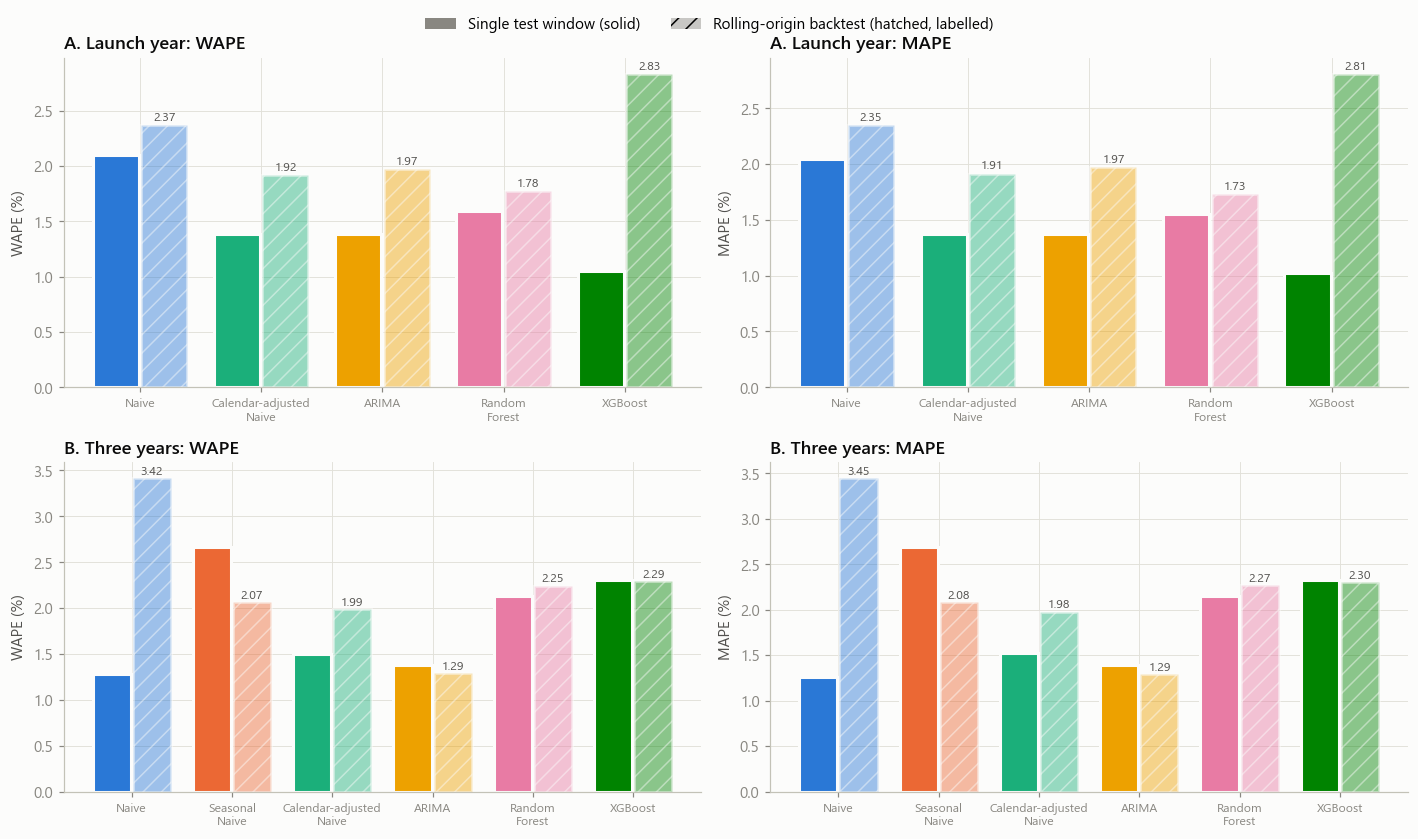

In [20]:
def metric_bars(ax, r, metric, title):
    keys = [k for k in MODEL_ORDER if r["models"][k]["available"]]
    x = np.arange(len(keys))
    test = [r["models"][k]["metrics_test"][metric] for k in keys]
    bt = [(r["models"][k]["backtest"]["metrics"] or {}).get(metric) for k in keys]
    cols = [MODEL_COLORS[k] for k in keys]
    ax.bar(x - 0.2, test, width=0.38, color=cols, edgecolor=SURFACE, linewidth=2)
    ax.bar(x + 0.2, bt, width=0.38, color=cols, alpha=0.45, hatch="//", edgecolor=SURFACE, linewidth=2)
    for xi, v in zip(x + 0.2, bt):
        ax.text(xi, v + 0.04, f"{v:.2f}", ha="center", color=INK_2, fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels([MODEL_LABELS[k].replace(" ", "\n", 1) for k in keys], fontsize=8)
    ax.set_title(title); ax.set_ylabel(f"{metric.upper()} (%)")


fig, axes = plt.subplots(2, 2, figsize=(13, 7.5))
metric_bars(axes[0, 0], res_launch, "wape", "A. Launch year: WAPE")
metric_bars(axes[0, 1], res_launch, "mape", "A. Launch year: MAPE")
metric_bars(axes[1, 0], res_full, "wape", "B. Three years: WAPE")
metric_bars(axes[1, 1], res_full, "mape", "B. Three years: MAPE")
from matplotlib.patches import Patch
fig.legend(handles=[Patch(facecolor=MUTED, label="Single test window (solid)"),
                    Patch(facecolor=MUTED, alpha=0.45, hatch="//", label="Rolling-origin backtest (hatched, labelled)")],
           loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.02))
plt.tight_layout(); plt.show()

**Interpretation, generated from the metrics.** It names the best model, the runner-up and the margin, and applies the parsimony rule: plan with the simplest model within 0.5 WAPE points of the best.

In [21]:
def ranking_sentence(r):
    snap = r["snapshot"]["best_model"]
    ranks = r["snapshot"]["ranking"]
    txt = f"**{snap['model']}** ranks first on {snap['basis']} ({snap['wape_pct']:.2f}%)"
    if snap.get("runner_up"):
        txt += f", ahead of {snap['runner_up']} ({snap['runner_up_wape_pct']:.2f}%, margin {snap['margin_pct_points']:.2f} points)"
    if snap.get("naive_wape_pct") is not None:
        txt += f"; the Naive benchmark scores {snap['naive_wape_pct']:.2f}%"
    txt += f". Last place: {ranks[-1]['model']} ({ranks[-1]['wape_pct']:.2f}%)."
    rec = r["snapshot"]["recommended_model"]
    if not rec["same_as_best"]:
        txt += f" **Recommended for planning: {rec['model']}** ({rec['wape_pct']:.2f}%), the {rec['rule']}."
    return txt


say(f'''**Interpretation.**
* **A. Launch year:** {ranking_sentence(res_launch)} With only 9 test errors per model in the backtest, gaps of a few tenths of a point are within noise. The honest conclusion is that the calendar-aware simple models and the Random Forest are effectively tied, and all of them beat Naive. When models tie, we plan with the simplest one (a *parsimony rule*): it is easier to explain and less likely to be fitting noise.
* **B. Three years:** {ranking_sentence(res_full)} With more history, ARIMA's selected order is {tuple(res_full['models']['arima']['params']['order'])}: a long-run average level adjusted for the days in each month. Because month-to-month changes are random noise around a stable level, averaging all of history beats carrying forward the last month.
* **Errors are small in absolute terms** (about 1-3%). The product sells at a very steady rate, so most of the remaining error is irreducible noise.''')

**Interpretation.**
* **A. Launch year:** **Random Forest** ranks first on backtest WAPE (1.78%), ahead of Calendar-adjusted Naive (1.92%, margin 0.14 points); the Naive benchmark scores 2.37%. Last place: XGBoost (2.83%). **Recommended for planning: Calendar-adjusted Naive** (1.92%), the simplest model whose backtest WAPE is within 0.5 points of the best. With only 9 test errors per model in the backtest, gaps of a few tenths of a point are within noise. The honest conclusion is that the calendar-aware simple models and the Random Forest are effectively tied, and all of them beat Naive. When models tie, we plan with the simplest one (a *parsimony rule*): it is easier to explain and less likely to be fitting noise.
* **B. Three years:** **ARIMA** ranks first on backtest WAPE (1.29%), ahead of Calendar-adjusted Naive (1.99%, margin 0.70 points); the Naive benchmark scores 3.42%. Last place: Naive (3.42%). With more history, ARIMA's selected order is (0, 0, 0): a long-run average level adjusted for the days in each month. Because month-to-month changes are random noise around a stable level, averaging all of history beats carrying forward the last month.
* **Errors are small in absolute terms** (about 1-3%). The product sells at a very steady rate, so most of the remaining error is irreducible noise.

## 9. Task 4: Forecasting the next 3 months

Each model is **refitted on all available data** and forecasts the next three months, with an uncertainty range where the model supports one:
* **analytic** (Naive family): from the spread of past month-to-month changes;
* **native** (ARIMA): statsmodels' prediction intervals;
* **empirical** (Random Forest, XGBoost): from the backtest errors at each step ahead. These are approximate, and only shown when at least 3 backtest errors exist per step.

In [22]:
def forecast_table(r):
    rows = []
    for k in MODEL_ORDER:
        m = r["models"][k]
        if not m["available"]:
            continue
        f = m["forecast"]
        for i, month in enumerate(f["months"]):
            rows.append({"model": m["label"], "month": month, "forecast": f["point"][i],
                         "80% low": f["lower80"][i] if f["lower80"] else None,
                         "80% high": f["upper80"][i] if f["upper80"] else None,
                         "95% low": f["lower95"][i] if f["lower95"] else None,
                         "95% high": f["upper95"][i] if f["upper95"] else None})
    return pd.DataFrame(rows).pivot_table(index="model", columns="month", values="forecast",
                                          sort=False).round(0), pd.DataFrame(rows)


fc_launch_wide, fc_launch_long = forecast_table(res_launch)
fc_full_wide, fc_full_long = forecast_table(res_full)
print("A. Launch year -> forecast for Jan-Mar 2022 (units)")
display(fc_launch_wide.astype("Int64"))
print("B. Three years -> forecast for Jan-Mar 2024 (units)")
display(fc_full_wide.astype("Int64"))

A. Launch year -> forecast for Jan-Mar 2022 (units)


month,2022-01,2022-02,2022-03
model,,,
Naive,160396,160396,160396
Calendar-adjusted Naive,160396,144874,160396
ARIMA,160396,143328,160396
Random Forest,160394,158892,162222
XGBoost,161150,158450,165033


B. Three years -> forecast for Jan-Mar 2024 (units)


month,2024-01,2024-02,2024-03
model,,,
Naive,156938,156938,156938
Seasonal Naive,164343,148449,159642
Calendar-adjusted Naive,162169,151707,162169
ARIMA,162825,152562,162825
Random Forest,162836,153051,163564
XGBoost,163955,153218,163362


**Fan chart.** History, the recommended model's 3-month forecast with 80% and 95% ranges, and the Naive forecast for reference. For the launch year we also overlay what actually happened in Jan-Mar 2022.

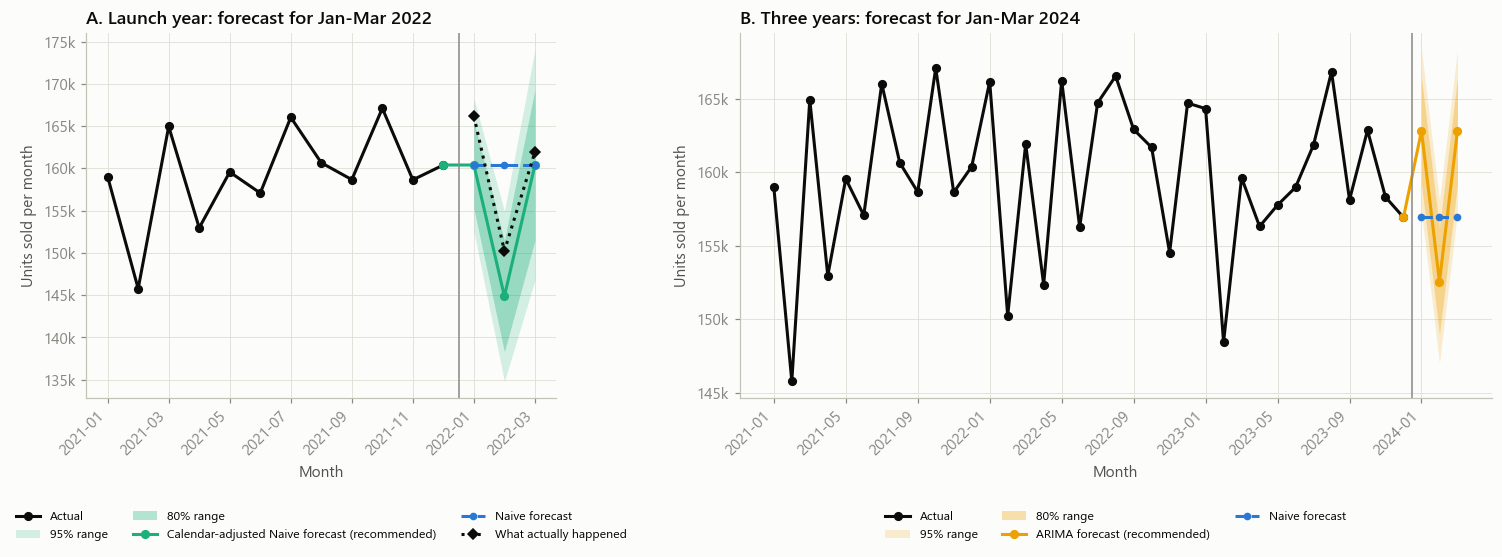

In [23]:
def fan_chart(ax, r, title, actual_after=None):
    hist = r["series"]
    months = [h["month"] for h in hist]
    best = r["recommended_model"]
    f = r["models"][best]["forecast"]
    n = len(months)
    xs_h, xs_f = np.arange(n), np.arange(n, n + len(f["months"]))
    ax.plot(xs_h, [h["units"] for h in hist], color=INK, marker="o", label="Actual")
    if f["lower95"]:
        ax.fill_between(xs_f, f["lower95"], f["upper95"], color=MODEL_COLORS[best], alpha=0.18, linewidth=0,
                        label="95% range")
        ax.fill_between(xs_f, f["lower80"], f["upper80"], color=MODEL_COLORS[best], alpha=0.32, linewidth=0,
                        label="80% range")
    ax.plot(np.r_[n - 1, xs_f], np.r_[hist[-1]["units"], f["point"]], color=MODEL_COLORS[best], marker="o",
            label=f"{MODEL_LABELS[best]} forecast (recommended)")
    nv = r["models"]["naive"]["forecast"]["point"]
    ax.plot(xs_f, nv, color=MODEL_COLORS["naive"], linestyle="--", marker="o", markersize=4, label="Naive forecast")
    if actual_after is not None:
        ax.plot(xs_f, actual_after, color=INK, marker="D", linestyle=":", label="What actually happened")
    ax.axvline(n - 0.5, color=MUTED, linewidth=1)
    month_ticks(ax, months + f["months"], 2 if n <= 15 else 4); thousands(ax)
    ax.set_title(title); ax.set_xlabel("Month"); ax.set_ylabel("Units sold per month")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=3, fontsize=8)


actual_q1_2022 = [r["units"] for r in full_records[12:15]]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw={"width_ratios": [1, 1.6]})
fan_chart(axes[0], res_launch, "A. Launch year: forecast for Jan-Mar 2022", actual_q1_2022)
fan_chart(axes[1], res_full, "B. Three years: forecast for Jan-Mar 2024")
plt.tight_layout(); plt.show()

### 9.1 A true out-of-sample check for the launch-year forecast

In real life the company would wait three months to learn whether the launch-year forecast was right. Our dataset already contains those months, so we can score every model's **Jan-Mar 2022** forecast against what actually happened. No model saw these months during training or model selection.

In [24]:
oos = []
for k in MODEL_ORDER:
    m = res_launch["models"][k]
    if not m["available"]:
        continue
    pt = m["forecast"]["point"]
    ev = fc.evaluate(actual_q1_2022, pt)
    inside = None
    if m["forecast"]["lower95"]:
        inside = int(sum(lo <= a <= hi for a, lo, hi in
                         zip(actual_q1_2022, m["forecast"]["lower95"], m["forecast"]["upper95"])))
    oos.append({"model": m["label"], "MAPE %": ev["mape"], "WAPE %": ev["wape"], "bias %": ev["bias"],
                "actuals inside 95% range": "n/a" if inside is None else f"{inside}/3"})
oos = pd.DataFrame(oos).set_index("model").round(2).sort_values("WAPE %")
oos

,MAPE %,WAPE %,bias %,actuals inside 95% range
model,,,,
Calendar-adjusted Naive,2.66,2.65,-2.65,3/3
ARIMA,3.01,2.97,-2.97,3/3
Random Forest,3.14,3.08,0.66,2/3
XGBoost,3.47,3.42,1.32,2/3
Naive,3.73,3.66,0.59,3/3


**Interpretation, generated from the out-of-sample results.**

In [25]:
feb_actual = actual_q1_2022[1]
feb_naive = res_launch["models"]["naive"]["forecast"]["point"][1]
covered = sum(1 for v in oos["actuals inside 95% range"] if v == "3/3")
rec_label = MODEL_LABELS[res_launch["recommended_model"]]
best_label = MODEL_LABELS[res_launch["best_model"]]
say(f'''**Interpretation.** On genuinely unseen months (Jan-Mar 2022), **{oos.index[0]}** was most accurate (WAPE {oos['WAPE %'].iloc[0]:.2f}%) and **{oos.index[-1]}** least accurate ({oos['WAPE %'].iloc[-1]:.2f}%).
* February 2022 had only 28 days: actual sales were {feb_actual:,.0f} units, while Naive forecast {feb_naive:,.0f}. Models without the calendar effect over-forecast short months.
* The backtest ranked **{best_label}** first, but the out-of-sample winner is **{oos.index[0]}**. The parsimony rule recommended **{rec_label}**. With so little data, the top of a backtest ranking is noisy, and choosing the simplest model among near-ties paid off.
* For {covered} of {len(oos)} models, all three actuals fell inside the 95% range, so the ranges are a sensible basis for safety stock.''')

**Interpretation.** On genuinely unseen months (Jan-Mar 2022), **Calendar-adjusted Naive** was most accurate (WAPE 2.65%) and **Naive** least accurate (3.66%).
* February 2022 had only 28 days: actual sales were 150,224 units, while Naive forecast 160,396. Models without the calendar effect over-forecast short months.
* The backtest ranked **Random Forest** first, but the out-of-sample winner is **Calendar-adjusted Naive**. The parsimony rule recommended **Calendar-adjusted Naive**. With so little data, the top of a backtest ranking is noisy, and choosing the simplest model among near-ties paid off.
* For 3 of 5 models, all three actuals fell inside the 95% range, so the ranges are a sensible basis for safety stock.

## 10. Task 6: Actual vs predicted sales

For every model we plot the actual sales (black), the forecasts made at each **backtest cut-off** (thin dashed lines: each is a 3-month forecast made with only the data available at that time), and the **main test-window forecast** (bold). A model that tracks the black line closely, at every cut-off, is reliable.

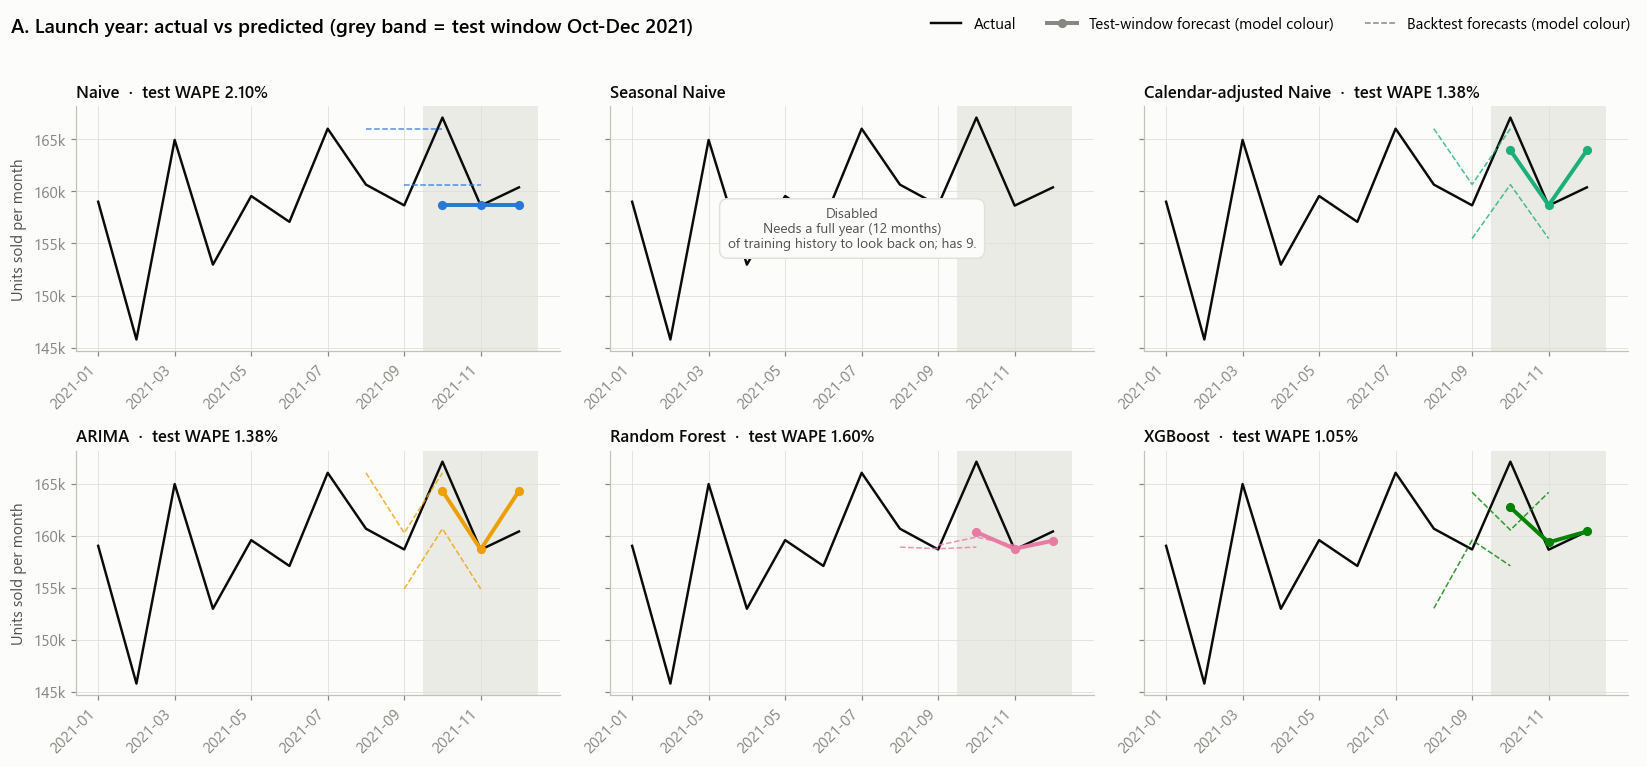

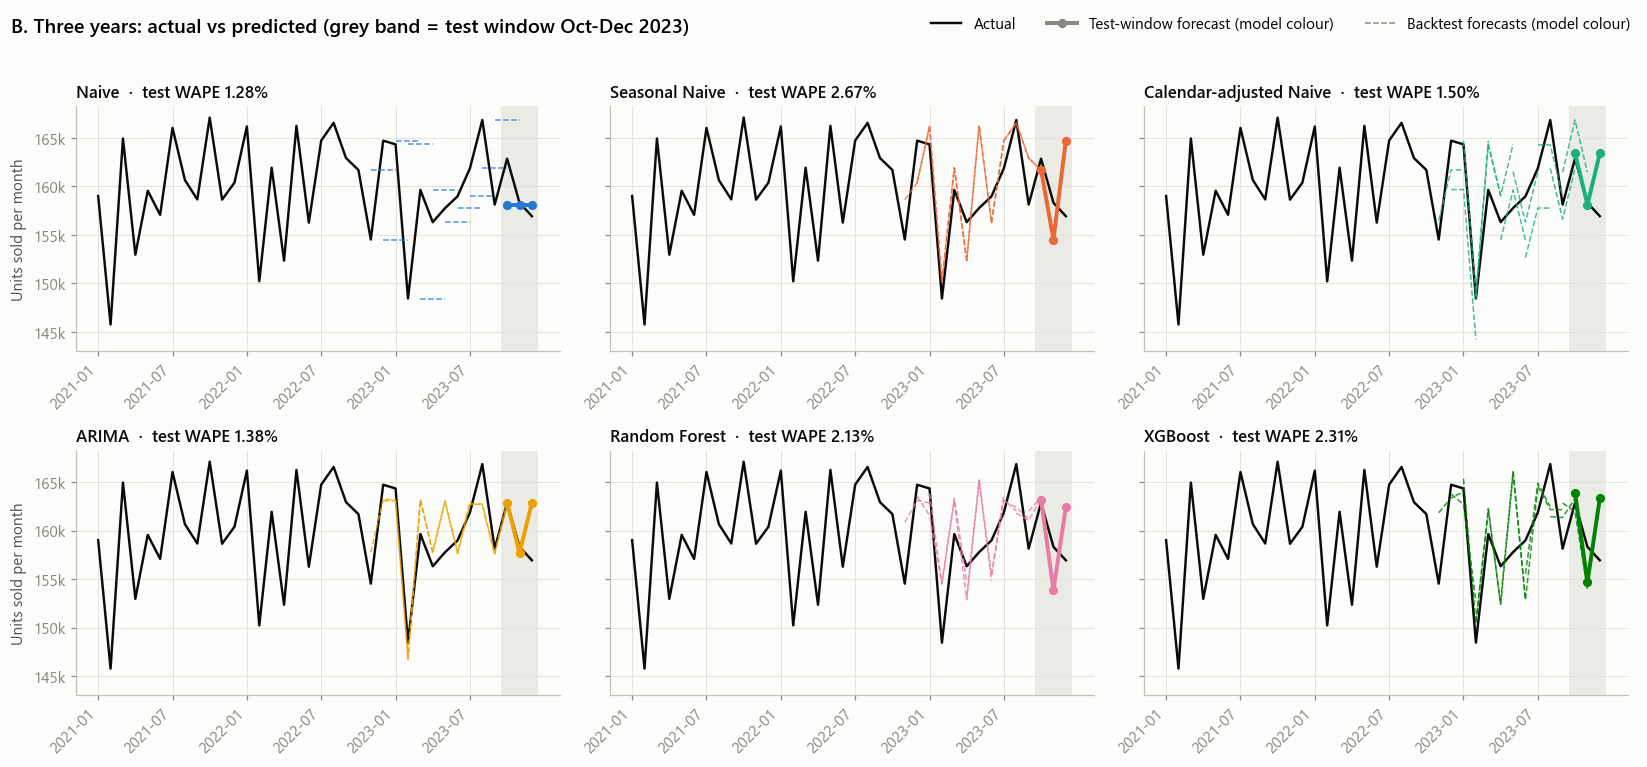

In [26]:
def actual_vs_predicted(r, title):
    fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey=True)
    hist = r["series"]
    months = [h["month"] for h in hist]
    pos = {m: i for i, m in enumerate(months)}
    for ax, k in zip(axes.flat, MODEL_ORDER):
        m = r["models"][k]
        ax.plot(range(len(months)), [h["units"] for h in hist], color=INK, linewidth=1.6, label="Actual")
        ax.axvspan(pos[r["meta"]["test_months"][0]] - 0.5, len(months) - 0.5, color=GRID, alpha=0.6, linewidth=0)
        if not m["available"]:
            ax.text(0.5, 0.5, "Disabled\n" + m["reason"].replace(" of training", "\nof training"),
                    transform=ax.transAxes, ha="center", va="center", color=INK_2, fontsize=9,
                    bbox=dict(facecolor=SURFACE, edgecolor=GRID, boxstyle="round,pad=0.6"))
        else:
            for fold in m["backtest"]["folds"]:
                xs = [pos[mm] for mm in fold["months"]]
                ax.plot(xs, fold["forecast"], color=MODEL_COLORS[k], linewidth=1, linestyle="--", alpha=0.8)
            t = m["test"]
            ax.plot([pos[mm] for mm in t["months"]], t["forecast"], color=MODEL_COLORS[k], linewidth=2.6,
                    marker="o")
        wape_txt = f"  ·  test WAPE {m['metrics_test']['wape']:.2f}%" if m["available"] else ""
        ax.set_title(m["label"] + wape_txt, fontsize=11)
        month_ticks(ax, months, 2 if len(months) <= 15 else 6); thousands(ax)
    for ax in axes[:, 0]:
        ax.set_ylabel("Units sold per month")
    from matplotlib.lines import Line2D
    fig.legend(handles=[Line2D([], [], color=INK, linewidth=1.6, label="Actual"),
                        Line2D([], [], color=MUTED, linewidth=2.6, marker="o", label="Test-window forecast (model colour)"),
                        Line2D([], [], color=MUTED, linewidth=1, linestyle="--", label="Backtest forecasts (model colour)")],
               loc="upper right", ncol=3, bbox_to_anchor=(1, 1.0))
    fig.suptitle(title, x=0.01, ha="left", fontsize=13, fontweight="semibold")
    plt.tight_layout(rect=(0, 0, 1, 0.96)); plt.show()


actual_vs_predicted(res_launch, "A. Launch year: actual vs predicted (grey band = test window Oct-Dec 2021)")
actual_vs_predicted(res_full, "B. Three years: actual vs predicted (grey band = test window Oct-Dec 2023)")

**Interpretation.** Naive (blue) lags one month behind and copies every random wiggle, so it misses the February dips and the rebounds. The Calendar-adjusted Naive and ARIMA forecasts move up and down with month length, which is exactly the systematic pattern in the data. The tree models follow the level reasonably well, but in the launch year their forecasts rest on very few rows. With more history they converge towards the same flat, calendar-shaped forecast that the simpler models produce directly.

## 11. Task 7: Interpretation with an LLM, based on real-time data

The brief requires an LLM that writes the interpretation **from the actual computed results**. Our design:

1. **Results snapshot.** The pipeline condenses its output into a compact, rounded JSON snapshot: data window, split, test and backtest MAPE/WAPE/bias for every model, forecasts with ranges, trend and seasonality statistics, regional shares, known limitations, and a list of verified **key facts** with the verdicts spelled out.
2. **Grounded prompt.** A shared system prompt (`prompts/interpretation_system.md`, also used by the dashboard) instructs the LLM to answer the three questions from the brief **using only numbers in the snapshot**, never to invent figures or causes, and to state limitations. It must return structured JSON.
3. **Grounding check.** Every number in the LLM's answer is extracted and matched against the snapshot. If more than two figures are not in the data, or if any p-value is wrong or contradicts its "significant / not significant" wording, the answer is rejected.
4. **Fallback.** If there is no key, a network error, a rate limit, a timeout, invalid JSON, or a failed grounding check, a **rule-based interpretation** built from the same snapshot is shown instead, clearly labelled.

**"Real-time data", concretely.** The interpretation is regenerated whenever the data changes. In §11.3 we simulate a new month of actual sales arriving (January 2022). The pipeline re-runs, the snapshot gets a new data version, and the LLM re-interprets. The dashboard does the same each time a month arrives in its live data feed or the user enters new figures.

> **Model and resilience.** The LLM is **NVIDIA Nemotron 3.5 Bolt E4B** (NVIDIA API Catalog, `NVIDIA_API_KEY` from the git-ignored `.env`, never displayed). It is a small, fast model (about 7 seconds per answer), so the snapshot includes **key facts**: pre-written, verified sentences that carry each verdict explicitly (for example "NOT statistically significant (p = 0.212)"), and the check rejects any wrong p-value or any sentence whose "significant / not significant" wording contradicts its own p-value. Temporary errors get one retry before the fallback.

In [27]:
SYSTEM_PROMPT = load_system_prompt(PROMPT_PATH)


def show_interpretation(result, title):
    it = result["interpretation"]
    badge = (f"LLM ({result['model']}, {result['latency_s']} s)" if result["source"] == "llm"
             else f"Rule-based fallback ({result['error']})")
    g = result["grounding"]
    recs = "\n".join(f"{i + 1}. {r}" for i, r in enumerate(it["recommendations"]))
    lims = "\n".join(f"- {r}" for r in it["limitations"])
    say(f'''### {title}
*Source: {badge} · numbers checked: {g['checked']}, verified: {len(g['verified'])}, not in data: {len(g['unverified'])} · confidence: {it['confidence']}*

**Q1. How well did the model capture seasonality or trends?**
{it['seasonality_trend']}

**Q2. Which model performed best and why?**
{it['best_model']}

**Q3. What recommendations would you give the company?**
{recs}

**Limitations**
{lims}''')


print("Snapshot sent to the LLM for the launch year (abridged):")
print(json.dumps({k: res_launch["snapshot"][k] for k in ("context", "split", "analysis", "best_model")}, indent=1))

Snapshot sent to the LLM for the launch year (abridged):
{
 "context": {
  "product": "Volvic Touch",
  "region": "All regions",
  "customer_type": "All customers",
  "view": "Launch year (first 12 months)",
  "data_version": 1,
  "unit": "units"
 },
 "split": {
  "train": "2021-01 to 2021-09",
  "n_train": 9,
  "test": "2021-10 to 2021-12",
  "test_size": 3,
  "horizon": 3,
  "backtest_origins": 3,
  "ranking_basis": "backtest WAPE"
 },
 "analysis": {
  "trend_pct_per_year": 2.32,
  "trend_p_value": 0.212,
  "trend_significant": false,
  "seasonality_p_value": null,
  "seasonality_significant": null,
  "seasonality_note": "Each calendar month has been observed only once, so a seasonal pattern cannot be separated from random noise (needs 24+ months).",
  "seasonal_peak_trough_pct": 5.57,
  "days_in_month_r2": 0.76,
  "acf_lag1": 0.05,
  "acf_bound": 0.57,
  "revenue_trend_pct_per_year": 2.54,
  "revenue_trend_p_value": 0.142
 },
 "best_model": {
  "model": "Random Forest",
  "basis": "

### 11.1 Interpretation of the launch year (the brief's scenario)

In [28]:
llm_launch = interpret(res_launch["snapshot"], SYSTEM_PROMPT)
show_interpretation(llm_launch, "Launch year (12 months) - forecast for Jan-Mar 2022")

### Launch year (12 months) - forecast for Jan-Mar 2022
*Source: LLM (nvidia/nemotron-3.5-bolt-e4b, 6.97 s) · numbers checked: 22, verified: 22, not in data: 0 · confidence: low*

**Q1. How well did the model capture seasonality or trends?**
The volume trend is +2.32% per year, NOT statistically significant (p = 0.212). Seasonality cannot be tested yet because each calendar month has been observed only once. The calendar effect is that the number of days in a month explains R² = 0.76 of the month-to-month variation. Revenue per day trend is +2.54% per year, NOT statistically significant (p = 0.142).

**Q2. Which model performed best and why?**
Random Forest performed best with 1.78% WAPE, beating the Naive benchmark of 2.37% by 0.59 percentage points. The runner-up is Calendar-adjusted Naive at 1.92% with a margin of 0.14 percentage points. The models are effectively tied. The planning model is Calendar-adjusted Naive because it is the simplest model whose backtest WAPE is within 0.5 points of the best.

**Q3. What recommendations would you give the company?**
1. Produce a total of 465,666 units based on the Calendar-adjusted Naive forecast.
2. Maintain safety stock within the 95% ranges: 2022-01 (152,520 to 168,272), 2022-02 (134,814 to 154,934), 2022-03 (146,755 to 174,037).
3. The planning-model test bias is +0.09%, meaning almost unbiased.
4. Distribute according to regional shares: Saarland 6.7%, Hessen 6.5%, Hamburg 6.4%.
5. Re-forecast as new months arrive.

**Limitations**
- The dataset is synthetic (simulated sales), so patterns reflect the simulator, not real consumers.
- Only 12 months of history: seasonality cannot be tested and machine-learning models have very few training rows.
- The test window is 3 months, so one unusual month can move MAPE noticeably.

### 11.2 Interpretation with three years of history

In [29]:
llm_full = interpret(res_full["snapshot"], SYSTEM_PROMPT)
show_interpretation(llm_full, "Three years (36 months) - forecast for Jan-Mar 2024")

### Three years (36 months) - forecast for Jan-Mar 2024
*Source: LLM (nvidia/nemotron-3.5-bolt-e4b, 7.52 s) · numbers checked: 24, verified: 24, not in data: 0 · confidence: high*

**Q1. How well did the model capture seasonality or trends?**
The volume trend is +0.21% per year and is NOT statistically significant (p = 0.538). Seasonality is NOT statistically significant (p = 0.417). The number of days in a month explains R² = 0.72 of the month-to-month variation, used by Calendar-adjusted Naive, ARIMA, Random Forest, and XGBoost. Revenue per day trend is +2.77% per year, statistically significant (p < 0.001).

**Q2. Which model performed best and why?**
ARIMA performed best with a backtest WAPE of 1.29%. The Naive benchmark WAPE is 3.42%, and the runner-up is Calendar-adjusted Naive at 1.99% (margin 0.7 points). The planning model is ARIMA, which is also the best model, so the parsimony rule does not differ.

**Q3. What recommendations would you give the company?**
1. Produce 478,211 units total, with 2024-01 at 162,825 units (95% range 157,290 to 168,359).
2. Maintain safety stock using the 95% ranges: 2024-01 (157,290 to 168,359), 2024-02 (147,027 to 158,097), 2024-03 (157,290 to 168,359).
3. The planning-model test bias is +1.11%, meaning over-forecast (risk of excess stock).
4. Distribute based on regional shares: Saarland 6.9%, Hamburg 6.5%, Thüringen 6.5%.
5. Re-forecast as new months arrive.

**Limitations**
- The dataset is synthetic (simulated sales), so patterns reflect the simulator, not real consumers.
- The test window is 3 months, so one unusual month can move MAPE noticeably.
- December 2023 contains 30 of 31 days because the data ends on 30 Dec 2023.

### 11.3 Real-time update: a new month of sales arrives

We append **January 2022**'s actual sales to the launch-year data, exactly as the dashboard's live data feed does. The whole pipeline (features, all six models, metrics, backtest, forecasts) re-runs. The snapshot carries a new data version and a description of the change, and the LLM interprets the *updated* results.

In [30]:
updated_records = full_records[:13]  # launch year + January 2022
ctx = context_for(updated_records, "Launch year + live data feed")
ctx.update({"data_version": 2,
            "last_change": f"New actual received: {updated_records[-1]['month']} = {int(updated_records[-1]['units']):,} units"})
res_live = run_pipeline(updated_records, CONFIG, ctx, regional_for(updated_records))

before = res_launch["snapshot"]["best_model"]
after = res_live["snapshot"]["best_model"]
print(f"Data version 1 -> 2 ({ctx['last_change']})")
print(f"Best model: {before['model']} ({before['wape_pct']}%) -> {after['model']} ({after['wape_pct']}%)")
print("New 3-month forecast window:", res_live["models"][res_live["best_model"]]["forecast"]["months"])

llm_live = interpret(res_live["snapshot"], SYSTEM_PROMPT)
show_interpretation(llm_live, "After January 2022 arrives (data version 2)")

Data version 1 -> 2 (New actual received: 2022-01 = 166,182 units)
Best model: Random Forest (1.78%) -> Random Forest (1.74%)
New 3-month forecast window: ['2022-02', '2022-03', '2022-04']


### After January 2022 arrives (data version 2)
*Source: LLM (nvidia/nemotron-3.5-bolt-e4b, 7.04 s) · numbers checked: 22, verified: 22, not in data: 0 · confidence: medium*

**Q1. How well did the model capture seasonality or trends?**
The volume trend is +2.77% per year, NOT statistically significant (p = 0.09). Seasonality cannot be tested yet because each calendar month has been observed only once. The calendar effect, based on the number of days in a month, explains R² = 0.75 of the month-to-month variation, and models using it are Calendar-adjusted Naive, ARIMA, Random Forest, and XGBoost. The revenue per day trend is +3.68% per year, statistically significant (p = 0.032), contrasting the volume trend.

**Q2. Which model performed best and why?**
Random Forest performed best with a backtest WAPE of 1.74%. The Naive benchmark WAPE is 2.6%, and the runner-up is Calendar-adjusted Naive at 1.99% (margin 0.25 points). The models are effectively tied because the margin is below 0.5 points. The planning model is Calendar-adjusted Naive because it is the simplest model whose backtest WAPE is within 0.5 points of the best.

**Q3. What recommendations would you give the company?**
1. Produce a total of 477,103 units based on the Calendar-adjusted Naive forecast.
2. Use the 95% ranges: 2022-02: 142,726 to 157,473; 2022-03: 154,637 to 177,727; 2022-04: 147,138 to 174,505.
3. The planning-model test bias is +2.21%, indicating a risk of excess stock.
4. Distribute based on regional shares: Saarland 6.6%, Hessen 6.4%, Hamburg 6.4%.
5. Re-forecast as new months arrive.

**Limitations**
- The dataset is synthetic (simulated sales), so patterns reflect the simulator, not real consumers.
- Only 13 months of history: seasonality cannot be tested and machine-learning models have very few training rows.
- The test window is 3 months, so one unusual month can move MAPE noticeably.

## 12. Business recommendations and limitations

The LLM's answers above are generated from the live numbers. The summary below brings the evidence together for the company. Every number is computed in this notebook.

In [31]:
bl, bf = res_launch["snapshot"]["best_model"], res_full["snapshot"]["best_model"]
best_full = res_full["models"][res_full["recommended_model"]]
rl = res_launch["snapshot"]["recommended_model"]
f = best_full["forecast"]
q_total = sum(f["point"])
top3 = res_full["regional_allocation"]["regions"][:3]
say(f'''**Answers to the three questions**

1. **Seasonality and trends.** There is no seasonality (ANOVA p = {stats_full['seasonality']['p_value']:.2f}) and no volume trend (p = {stats_full['trend_units_per_day']['p_value']:.2f}) in three years of data. The only systematic pattern is the **number of days in each month** (R² = {stats_full['calendar']['r2']:.2f}). Models that use it (Calendar-adjusted Naive, ARIMA with the days regressor) capture the real pattern. Naive and Seasonal Naive copy noise.
2. **Best model.** In the launch year, **{bl['model']}** ranked first ({bl['wape_pct']:.2f}% backtest WAPE), but within noise of the calendar-aware models, so we plan with **{rl['model']}** ({rl['wape_pct']:.2f}%), the simplest of the tied models{" - and it was also the most accurate on the unseen months Jan-Mar 2022" if oos.index[0] == rl["model"] else ""}. With three years of data, **{bf['model']}** is clearly best ({bf['wape_pct']:.2f}%, against {bf.get('naive_wape_pct', float('nan')):.2f}% for Naive). Simple, calendar-aware models win because demand is a stable level plus random noise. There is nothing complex to learn, and the ML models' extra flexibility mainly fits noise.
3. **Recommendations.**
   * **Production:** plan {f['months'][0]} to {f['months'][-1]} at about **{q_total:,.0f} units** ({', '.join(f'{m}: {p:,.0f}' for m, p in zip(f['months'], f['point']))}). Set monthly targets **per sales day**, so February is planned about 10% lower than 31-day months.
   * **Safety stock:** size buffers from the forecast ranges, not from a fixed percentage. Errors of about {bf['wape_pct']:.1f}% (WAPE) mean modest buffers suffice for this steady product.
   * **Distribution:** allocate national volume by regional share. The top three states, {', '.join(f"{r['region']} ({r['share'] * 100:.1f}%)" for r in top3)}, should receive proportionally more stock. B2B accounts for most volume, so plan bulk deliveries around B2B order cycles.
   * **Pricing insight:** revenue per day is growing ({stats_full['revenue_trend']['pct_per_year']:+.2f}%/yr) while volume is flat. Growth is coming from price, so volume-growth initiatives, not production capacity, are the strategic lever.
   * **Process:** start a new product with **simple, calendar-aware models**, re-forecast every month as actuals arrive, and only adopt ML once a backtest shows it consistently beats the simple benchmark.''')

**Answers to the three questions**

1. **Seasonality and trends.** There is no seasonality (ANOVA p = 0.42) and no volume trend (p = 0.54) in three years of data. The only systematic pattern is the **number of days in each month** (R² = 0.72). Models that use it (Calendar-adjusted Naive, ARIMA with the days regressor) capture the real pattern. Naive and Seasonal Naive copy noise.
2. **Best model.** In the launch year, **Random Forest** ranked first (1.78% backtest WAPE), but within noise of the calendar-aware models, so we plan with **Calendar-adjusted Naive** (1.92%), the simplest of the tied models - and it was also the most accurate on the unseen months Jan-Mar 2022. With three years of data, **ARIMA** is clearly best (1.29%, against 3.42% for Naive). Simple, calendar-aware models win because demand is a stable level plus random noise. There is nothing complex to learn, and the ML models' extra flexibility mainly fits noise.
3. **Recommendations.**
   * **Production:** plan 2024-01 to 2024-03 at about **478,211 units** (2024-01: 162,825, 2024-02: 152,562, 2024-03: 162,825). Set monthly targets **per sales day**, so February is planned about 10% lower than 31-day months.
   * **Safety stock:** size buffers from the forecast ranges, not from a fixed percentage. Errors of about 1.3% (WAPE) mean modest buffers suffice for this steady product.
   * **Distribution:** allocate national volume by regional share. The top three states, Saarland (6.9%), Hamburg (6.5%), Thüringen (6.5%), should receive proportionally more stock. B2B accounts for most volume, so plan bulk deliveries around B2B order cycles.
   * **Pricing insight:** revenue per day is growing (+2.77%/yr) while volume is flat. Growth is coming from price, so volume-growth initiatives, not production capacity, are the strategic lever.
   * **Process:** start a new product with **simple, calendar-aware models**, re-forecast every month as actuals arrive, and only adopt ML once a backtest shows it consistently beats the simple benchmark.

**Limitations to keep in mind**
* **Synthetic data.** The sales are simulated, so the absence of seasonality reflects the simulator. Real flavoured-water demand typically peaks in summer, and with real data the same pipeline would detect and model that.
* **Small samples.** The launch year has 12 points: seasonality cannot be tested, the ML models train on 6-9 rows, and a 3-month test window means one unusual month can move MAPE by a point or more. The rolling-origin backtest reduces but does not remove this.
* **Partial month.** December 2023 has 30 of 31 days. It is handled through the observed day count, not by inventing data.
* **Regional noise.** Single-state series are 3-5 times noisier than the national series. Regional plans should come from allocation of the national forecast.
* **Interval quality.** The Random Forest and XGBoost ranges are empirical approximations from a few backtest errors.

## 13. Export for the dashboard

The dashboard cannot load the 789 MB raw file, so we export:
* `monthly_water.json`: monthly units and revenue for every product x region x customer type (the dashboard sums any filter combination in the browser);
* `snapshot_default.json`: the full pipeline result for the dashboard's opening view (launch year), shown instantly while the in-browser Python engine loads;
* `parity_fixtures.json`: results for several configurations. The dashboard's test suite checks that its in-browser engine reproduces them exactly.

In [32]:
DASHBOARD_DATA.mkdir(parents=True, exist_ok=True)
info = export_dashboard_data(water, days, DASHBOARD_DATA / "monthly_water.json",
                             source={"dataset": "Beverage Sales (Kaggle, sebastianwillmann)", "license": "MIT",
                                     "category": "Water", "synthetic": True,
                                     "note": "December 2023 contains 30 observed days (data ends 2023-12-30)."})
print("monthly_water.json:", info)

with open(DASHBOARD_DATA / "snapshot_default.json", "w", encoding="utf-8") as fh:
    json.dump(res_launch, fh, ensure_ascii=False, separators=(",", ":"))

parity_cases = {
    "launch_default": (launch_records, CONFIG, None),
    "full_default": (full_records, CONFIG, None),
    "launch_plus_jan2022": (updated_records, CONFIG, None),
    "full_test6_h6": (full_records, PipelineConfig(test_size=6, horizon=6), None),
    "bayern_b2c_24": (build_series(water, days, PRODUCT, region="Bayern", customer_type="B2C")[:24], CONFIG, None),
}
fixtures = {}
for name, (recs, cfg, _) in parity_cases.items():
    out = run_pipeline(recs, cfg)
    fixtures[name] = {"input": {"records": [{k: r[k] for k in ("month", "units", "days", "revenue") if k in r}
                                            for r in recs],
                                "test_size": cfg.test_size, "horizon": cfg.horizon},
                      "expected": {k: out[k] for k in ("models", "ranking", "best_model", "analysis", "features")}}
with open(DASHBOARD_DATA / "parity_fixtures.json", "w", encoding="utf-8") as fh:
    json.dump(fixtures, fh, ensure_ascii=False, separators=(",", ":"))

for p in sorted(DASHBOARD_DATA.glob("*.json")):
    print(f"{p.name:24s} {p.stat().st_size / 1024:8.1f} KB")

monthly_water.json: {'bytes': 136648, 'products': 9, 'regions': 16, 'months': 36}


monthly_water.json          133.4 KB
parity_fixtures.json        133.2 KB
snapshot_default.json        26.6 KB


**Done.** All seven lab tasks are complete, with an LLM interpretation grounded in the computed results and regenerated when new data arrives. The same `forecasting_core` engine powers the interactive dashboard.